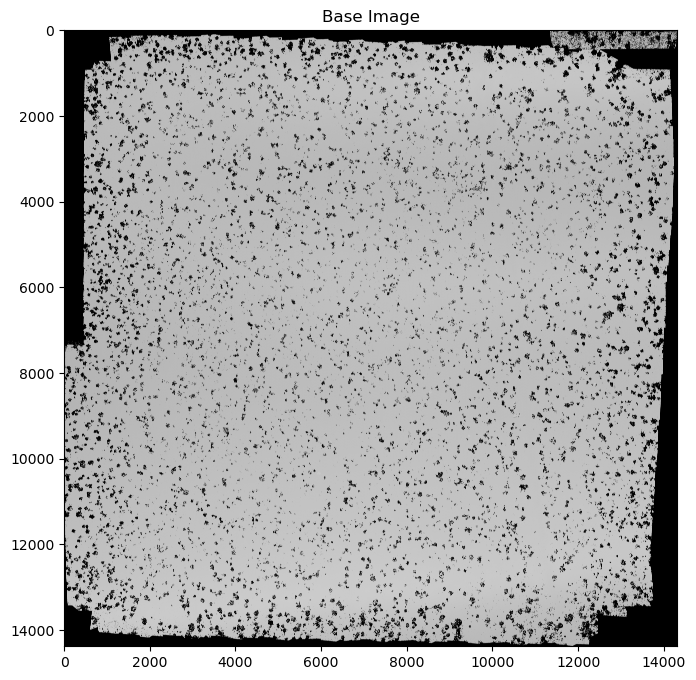

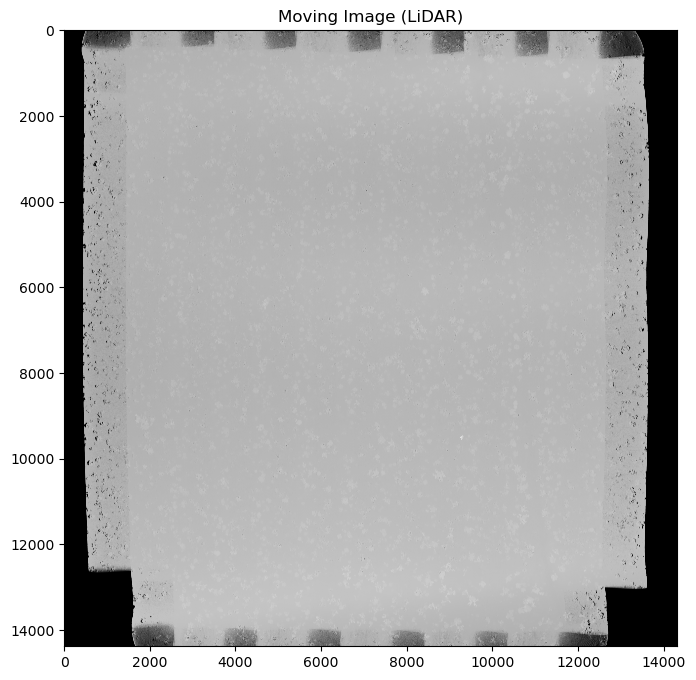

In [ ]:
import sys
import numpy as np
import rasterio
import time
import pylab as pl
from pathlib import Path

# === GeFolki dependencies === worksation
# sys.path.append('/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python')
# === GeFolki dependencies === NVIDIA
sys.path.append('/home/nvidia/projects/fvc_structure/phase_2_lidar_coregistration/gefolki/python')

from python.algorithm import EFolki
from python.tools import wrapData

# === Configuration ===
Base_band = 0

# === Input paths === workstation
# base_image_path = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")
# moving_image_path = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif")


# === Input paths === NVIDIA
base_image_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")
moving_image_path = Path("/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif")


# === Simplified and Corrected Load Function ===
def load_data_and_mask(path, band_idx):
    """
    Loads raster data and, crucially, also returns a boolean 'mask'
    that perfectly preserves the footprint of where the valid data is.
    """
    with rasterio.open(path) as src:
        if band_idx >= src.count:
            raise ValueError(f"Band {band_idx} is out of bounds.")
        
        # Get a True/False mask of the valid data footprint (255=valid, 0=nodata)
        valid_mask = src.read_masks(band_idx + 1) > 0
        
        # Read the data and set nodata areas to 0 for processing
        arr = src.read(band_idx + 1).astype(np.float32)
        arr[~valid_mask] = 0
        return arr, valid_mask

# === Load base and moving images, capturing their masks ===
base_data, base_mask = load_data_and_mask(base_image_path, Base_band)
moving_data, moving_mask = load_data_and_mask(moving_image_path, 0)

# === Plot initial data ===
pl.figure(figsize=(8,8)); pl.imshow(base_data, cmap='gray'); pl.title("Base Image")
pl.figure(figsize=(8,8)); pl.imshow(moving_data, cmap='gray'); pl.title("Moving Image (LiDAR)")
pl.show()

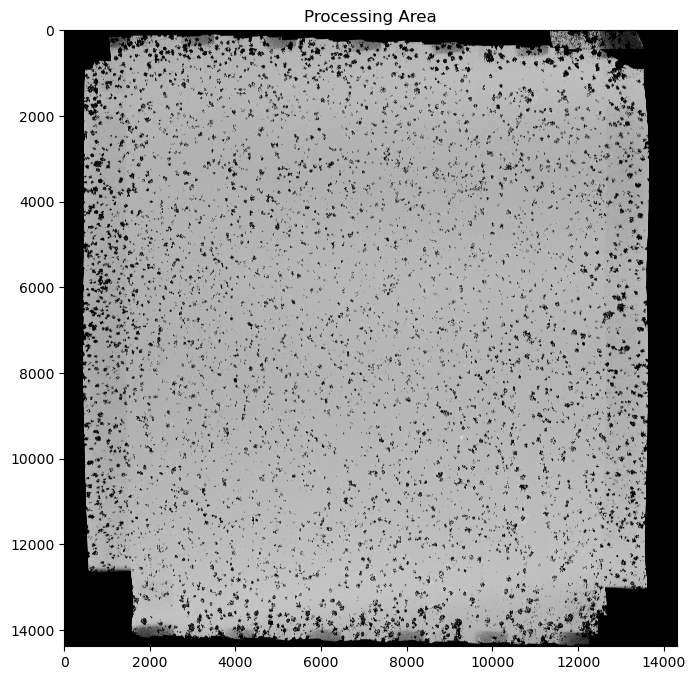

In [ ]:
# === Define processing area ===
# The area to process is where BOTH images have valid data
processing_mask = base_mask & moving_mask
base_data[~processing_mask] = 0
moving_data[~processing_mask] = 0

pl.figure(figsize=(8,8)); pl.imshow(moving_data, cmap='gray'); pl.title("Processing Area")
pl.show()

Calculating flow...



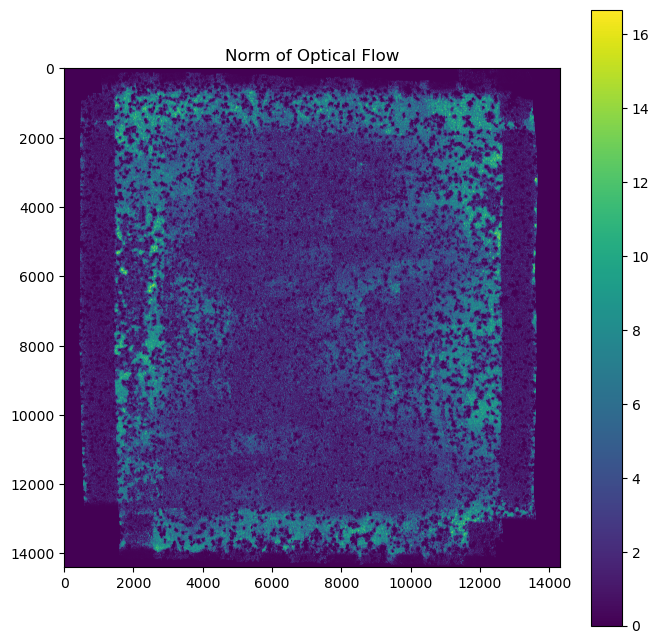

In [ ]:
# === Calculate optical flow ===
print("Calculating flow...\n")
t0 = time.perf_counter()
# --- BEFORE --- L1 displacement up to ~64 pixels
u, v = EFolki(base_data, moving_data, iteration=8, radius=[16, 8, 4], rank=4, levels=6)

# --- AFTER (for displacements > 64 pixels) ---
# Increased levels to 7 (handles up to 128px displacement)
# Added a larger radius '32' for the new, coarsest pyramid level
# u, v = EFolki(base_data, moving_data, 
#               iteration=8, 
#               radius=[32, 16, 8, 4],  # Adjust list size/values
#               rank=4, 
#               levels=7)              # Key change for large displacement
# t1 = time.perf_counter()
# print(f"✅ Flow calculated in {(t1 - t0)/60:.3f} minutes")

# Mask the flow vectors for cleaner plotting
u[~processing_mask] = 0
v[~processing_mask] = 0

N = np.sqrt(u**2 + v**2)
pl.figure(figsize=(8,8)); pl.imshow(N, cmap='viridis'); pl.title("Norm of Optical Flow"); pl.colorbar()
pl.show()

Registering image...



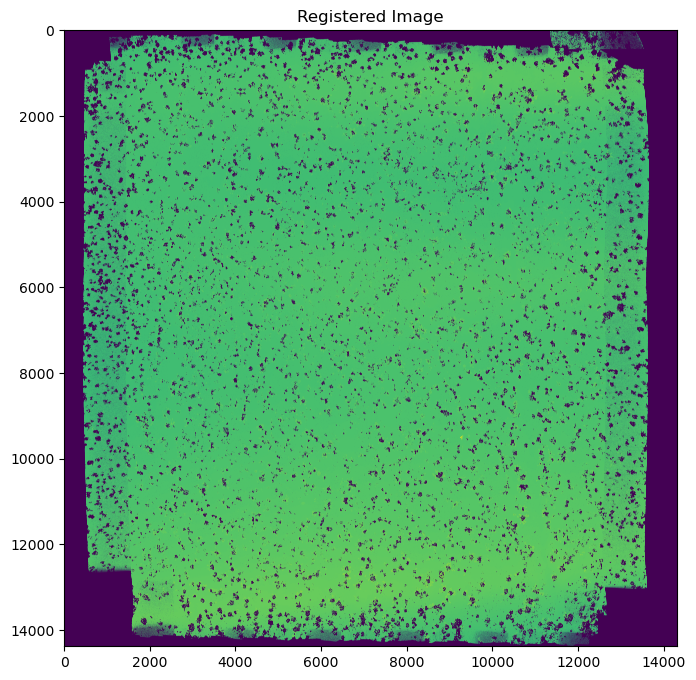

In [ ]:
# === Register the LiDAR data AND its footprint ===
print("Registering image...\n")
# 1. Warp the LiDAR elevation data
imag_reg = wrapData(moving_data, u, v)

# 2. Warp the LiDAR's original footprint (its mask) using the SAME flow field.
#    This is the key step to correctly track where the nodata areas should be.
warped_mask = wrapData(moving_mask.astype('float32'), u, v) > 0.5

pl.figure(figsize=(8,8)); pl.imshow(imag_reg); pl.title("Registered Image")
pl.show()

In [ ]:
# === Save flow and the correctly registered image ===
print("\n--- Saving Results ---")
flow_dir = base_image_path.parent
aligned_path = moving_image_path.with_name(moving_image_path.stem + "_coreg.tif")

# 1. Get the metadata profile from the original base image to set the output grid.
with rasterio.open(base_image_path) as src:
    profile = src.profile
    nodata_value = src.nodata if src.nodata is not None else -9999

# 2. Use the 'warped_mask' to apply nodata values to the registered image.
#    This correctly removes the "extra data is 0" artifact.
imag_reg[~warped_mask] = nodata_value

# 3. Update profile for float32 output and write the file.
profile.update(dtype='float32', nodata=nodata_value)
with rasterio.open(aligned_path, "w", **profile) as dst:
    dst.write(imag_reg.astype('float32'), 1)

print(f"✅ Registered image saved to: {aligned_path}")
print("   (The output correctly preserves the smaller LiDAR footprint)")

# --- Save the flow fields ---
np.save(flow_dir / "flow_u_03_l1.npy", u)
np.save(flow_dir / "flow_v_03_l1.npy", v)
print(f"💾 Flow fields saved to: {flow_dir}")


--- Saving Results ---
✅ Registered image saved to: /data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif
   (The output correctly preserves the smaller LiDAR footprint)
💾 Flow fields saved to: /data/calperumResearch/site1_1_DD0001/imagery/dsm
